# Сравнение: FEM → coarse Galerkin → GMsFEM → neural operators

Фиксируем одну и ту же задачу для каждого held-out примера: DG0 A,n, k, направление и исходную тонкую FEM-сетку. Метрика всех методов:
\[
\|u_{method}^s-u_{FEM}^s\|_M/\|u_{FEM}^s\|_M.
\]
Fine FEM — reference, а не точное аналитическое решение. Его почти нулевая ошибка к собственным меткам не означает превосходство по точности. Coarse baseline — Q1 traces, интерполированные в fine P1 и решённые Galerkin-проекцией; это не самостоятельная coarse P1-сетка. GMsFEM использует существующие snapshots Type 1/2 и спектральные пространства `gmsfem.offline`.

Основная paired-таблица содержит по одному направлению **трёх** test-частот для всех методов. Полная neural-таблица по всем 1280 test-примерам показывается отдельно. Повторяющиеся направления одной частоты статистически зависимы. Числа параметров сетей и FEM DOF не являются одной и той же величиной.

**Статичная задача:** геометрия и исходная среда №0 фиксированы; A,n и DG0-материалы одинаковы во всех примерах. Меняются k и θ. Один medium_id=0, разбиение по frequency_id: 670/170/160 частот (5360/1360/1280 полей). 1000 частот × 8 направлений = 8000 полей на полосу. Этот эксперимент проверяет интерполяцию параметров волны на одной среде.

**Randomized SVD:** POD_METHOD="randomized"; FEM-данные общие с полным SVD, результаты сохраняются только в randomized/runs. Chebyshev и FNO используют те же определения операторов.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from neural_operator.randomized.settings import (BASE, N_FREQUENCIES, N_DIRECTIONS, DATASET_TAG, POD_METHOD,
    LOW_DATA_DIR, HIGH_DATA_DIR, LOW_RUNS, HIGH_RUNS, SVD_RUNS, COMPARISON_RUNS)
DATA_DIR = LOW_DATA_DIR
RUNS = LOW_RUNS
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.data import load_dataset, write_dataset_info
from neural_operator.plotting import display_table, plot_prediction, plot_history


In [2]:
from neural_operator.experiments import compare_methods
from neural_operator.diagnostics import write_csv, transfer_diagnostics
dataset = load_dataset(DATA_DIR, mmap=True)
OUT = COMPARISON_RUNS
METHODS = ['svd']  # Add chebyshev/fno after their training notebooks finish.
run_dirs = {method: RUNS / method for method in METHODS}
paired, summaries, neural_full = compare_methods(dataset, run_dirs, OUT,
    n_groups=3, n_coarse=4, modes=(1, 2, 4), basis_types=(1, 2))
display_table(summaries)


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_low_frequency_1000x8/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_low_frequency_1000x8/etal.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_low_frequency_1000x8/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_low_frequency_1000x8/etal.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_low_frequency_1000x8/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/static_low_frequency_1000x8/etal.msh'


method,mean,median,p95,max,paired_samples,online_seconds_mean,offline_seconds_mean,assembly_seconds_mean,training_seconds
Fine FEM reference,0,0,0,0,3,0.015456,0,0.34475,0
Coarse Q1 traces in fine P1,0.16728,0.16758,0.16836,0.16845,3,0.0012441,0.00073694,0.34475,0
"GMsFEM Type 1, M=1",0.16363,0.16404,0.16523,0.16537,3,0.0011911,0.23152,0.34475,0
"GMsFEM Type 1, M=2",0.14598,0.14614,0.14769,0.14786,3,0.0020663,0.23152,0.34475,0
"GMsFEM Type 1, M=4",0.079725,0.079807,0.08168,0.081888,3,0.0051118,0.23152,0.34475,0
"GMsFEM Type 2, M=1",0.16656,0.16681,0.16908,0.16934,3,0.0011739,0.23182,0.34475,0
"GMsFEM Type 2, M=2",0.14897,0.14886,0.15055,0.15074,3,0.002061,0.23182,0.34475,0
"GMsFEM Type 2, M=4",0.074408,0.074364,0.075814,0.075976,3,0.0049766,0.23182,0.34475,0
SVD-SNO,0.021522,0.022598,0.024361,0.024557,3,0.010447,25.503,0,74.216


## Полный test только для нейрооператоров

Времена warm inference включают кодирование входа, вызов модели и восстановление FEM-поля. Для GMsFEM отдельно сохранены assembly, построение базиса и полный online solve с реконструкцией. Базис строится один раз до максимального M серии; соответствующая стоимость указывается во всех строках серии. Для фиксированных A базис Type 1 можно переиспользовать между частотами; Type 2 зависит от k. Здесь offline cost измеряется при каждом построении в benchmark. Training и preprocessing сетей показаны отдельно и не скрыты в оценке ускорения.


In [3]:
display_table(neural_full)
transfer_rows = transfer_diagnostics(dataset, dataset.split_indices()[2], resolution=32)
write_csv(OUT / 'transfer_test.csv', transfer_rows)
display_table(transfer_rows)


method,mean,median,p95,max,samples,media,groups,split_strategy,batch_seconds_per_sample,single_seconds_median,preprocessing_seconds,training_seconds,parameters
SVD-SNO,0.0096139,0.0088239,0.016792,0.02948,1280,1,160,frequency,0.00010925,0.00049358,25.503,74.216,3110


grid,resolution,field,mean_fem_l2,p95_fem_l2
uniform,32,A,0.0066646,0.0066646
uniform,32,n,0.032489,0.032489
uniform,32,u_scat,0.02627,0.02841
chebyshev,32,A,0.01,0.01
chebyshev,32,n,0.047662,0.047662
chebyshev,32,u_scat,0.041418,0.04579


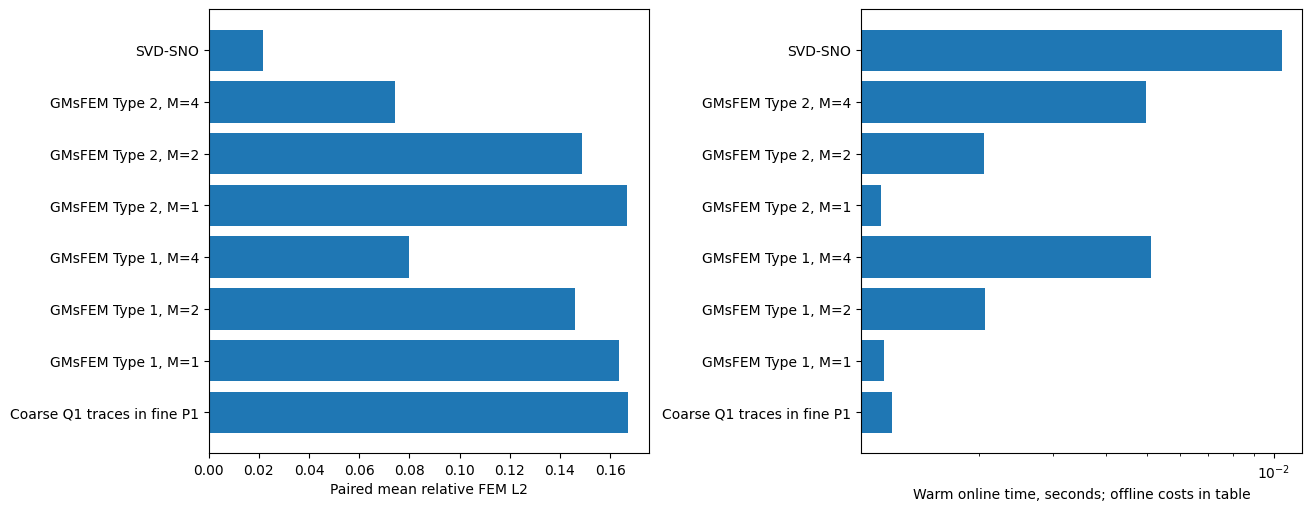

In [4]:
visible = [row for row in summaries if row['method'] != 'Fine FEM reference']
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
labels = [r['method'] for r in visible]
y = np.arange(len(labels))
axes[0].barh(y, [r['mean'] for r in visible]); axes[0].set_yticks(y, labels)
axes[0].set(xlabel='Paired mean relative FEM L2')
axes[1].barh(y, [r['online_seconds_mean'] for r in visible]); axes[1].set_yticks(y, labels)
axes[1].set(xscale='log', xlabel='Warm online time, seconds; offline costs in table')
fig.savefig(OUT / 'paired_comparison.png', dpi=160)
plt.show()


Небольшой seed-фиксированный эксперимент не определяет универсальный рейтинг методов. На локальные GMsFEM пространства влияют число мод и локальные резонансы; на нейрооператоры — число сред, пространственный перенос и tuning budget. Статьи и точные отличия реализации: [docs/references.md](../docs/references.md).
